# Render Speed Analysis

These analyses were done on a 7800x3d.

## Multi-Threading

Let's render the following image!
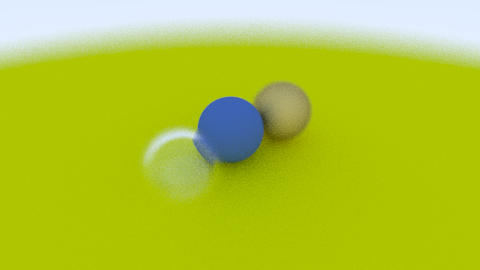

1 threads
20.50 seconds
2 threads
13.70 seconds
4 threads
8.87 seconds
8 threads
5.54 seconds
12 threads
4.54 seconds
16 threads
4.19 seconds
32 threads
3.90 seconds
64 threads
3.76 seconds
128 threads
3.82 seconds


Text(0.5, 1.0, 'Render Time vs. Thread Count (Image Width: 480)')

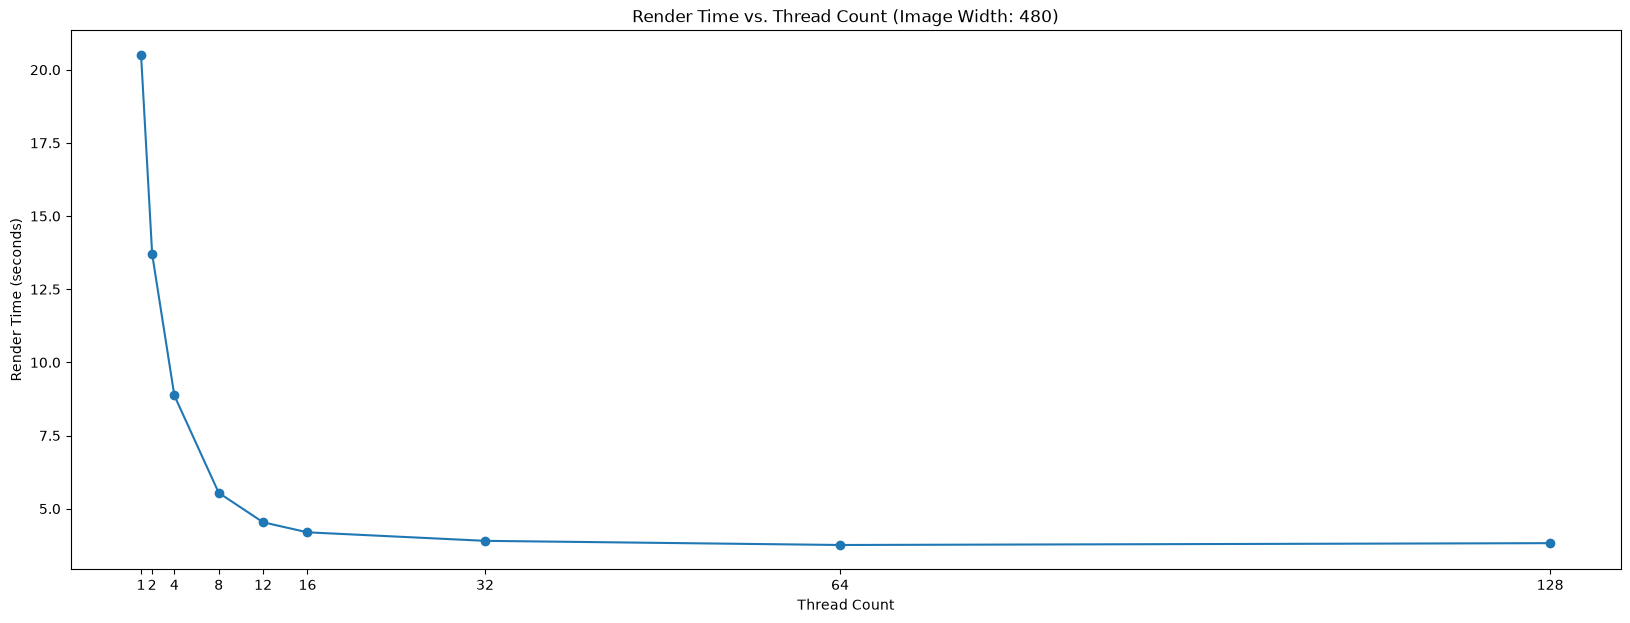

In [ ]:
import matplotlib.pyplot as plt
import subprocess, time

exe = r"..\src\build\Debug\main.exe"  
image_width = 480
thread_counts = [1, 2, 4, 8, 12, 16, 32, 64, 128]
times = [] 

for n in thread_counts:
    print(f"{n} threads")
    start = time.perf_counter()
    subprocess.run(
        [exe, str(image_width), str(n)],
        stdout=subprocess.DEVNULL, 
        stderr=subprocess.DEVNULL
    )
    end = time.perf_counter()
    times.append(end - start)
    print(f"{times[-1]:.2f} seconds")

plt.figure(figsize=(20, 7))
plt.plot(thread_counts, times)
plt.scatter(thread_counts, times)
plt.xticks(thread_counts)
plt.xlabel("Thread Count")
plt.ylabel("Render Time (seconds)")
plt.title(f"Render Time vs. Thread Count (Image Width: {image_width})")


## Bounding Volume Hierarchies